### Import Libraries

In [1]:
# for manipulations
import numpy as np
import pandas as pd

In [2]:
# for data visualizations
import matplotlib.pyplot as plt
plt.rcParams['axes.autolimit_mode'] = 'round_numbers'
plt.style.use('fivethirtyeight')

In [3]:
# lets import the warnings library so that we can avoid warnings
import warnings
warnings.filterwarnings('ignore')

In [4]:
# Custom Function
from custom_function import *

In [5]:
# For Normalization
from sklearn.preprocessing import MinMaxScaler

### Loading

#### 1. Food Price

In [6]:
food_price = get_dataset('\\Datasets\\wfp_food_prices_mmr(Cleaned).csv')
food_price.drop(['latitude', 'longitude'],  axis='columns', inplace=True)
food_price.head()

,date,region,city,market,category,commodity,Exact Commodity,Quality,unit,priceflag,pricetype,currency,price,usdprice
0,1/15/2008,Kachin,Myitkyina,Wai Maw,cereals and tubers,Rice (low quality),Rice,low quality,KG,actual,Retail,MMK,400.00,0.2247
1,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (chicken),chicken,NaN,KG,actual,Retail,MMK,3636.36,2.0429
2,1/15/2008,Kachin,Myitkyina,Wai Maw,"meat, fish and eggs",Meat (pork),pork,NaN,KG,actual,Retail,MMK,3636.36,2.0429
3,1/15/2008,Kachin,Myitkyina,Wai Maw,miscellaneous food,Salt,Salt,NaN,KG,actual,Retail,MMK,242.42,0.1362
4,1/15/2008,Kachin,Myitkyina,Wai Maw,vegetables and fruits,Onions,Onions,NaN,KG,actual,Retail,MMK,969.70,0.5448


In [7]:
food_price = food_price[['date', 'usdprice']]
food_price['date'] = pd.to_datetime(food_price['date'])
food_price.columns = ['date', 'food_price']
food_price = food_price.set_index('date')
food_price = food_price.resample('AS-JAN').mean()
food_price.head()

,food_price
date,
2008-01-01,0.563348
2009-01-01,0.452433
2010-01-01,0.505708
2011-01-01,0.546463
2012-01-01,0.467904


#### 2. Food imports Price Dataset

In [8]:
temp_food_imports = get_dataset('\\Datasets\\food_imports_percentage.csv')
temp_food_imports.head()

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
0,Aruba,ABW,Food imports (% of merchandise imports),TM.VAL.FOOD.ZS.UN,NaN,NaN,NaN,NaN,NaN,NaN,...,27.942489,31.466398,31.703066,27.918299,30.572758,29.871959,29.570403,27.729279,28.326863,30.605553
1,Africa Eastern and Southern,AFE,Food imports (% of merchandise imports),TM.VAL.FOOD.ZS.UN,NaN,NaN,NaN,NaN,NaN,NaN,...,10.960727,10.583083,9.949199,9.548348,9.726567,11.435855,11.898507,11.008575,10.919747,12.221672
2,Afghanistan,AFG,Food imports (% of merchandise imports),TM.VAL.FOOD.ZS.UN,NaN,NaN,7.835267,13.119864,17.335841,17.099851,...,14.029271,4.276023,7.546840,9.513261,19.227124,23.559998,36.793447,34.033057,26.915839,NaN
3,Africa Western and Central,AFW,Food imports (% of merchandise imports),TM.VAL.FOOD.ZS.UN,NaN,NaN,18.032962,16.413429,15.592313,14.123768,...,22.996573,19.250997,17.501354,17.464876,16.813443,16.062405,18.927268,16.602416,15.978359,NaN
4,Angola,AGO,Food imports (% of merchandise imports),TM.VAL.FOOD.ZS.UN,NaN,NaN,19.341476,NaN,NaN,NaN,...,18.596121,20.067915,17.754019,16.980079,13.185629,13.714861,17.735179,20.436471,19.293662,NaN


In [9]:
temp_food_imports = temp_food_imports[temp_food_imports['Country Code'] == 'MMR']
temp_food_imports

,Country Name,Country Code,Indicator Name,Indicator Code,1960,1961,1962,1963,1964,1965,...,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020
160,Myanmar,MMR,Food imports (% of merchandise imports),TM.VAL.FOOD.ZS.UN,NaN,NaN,13.426894,12.322681,29.384945,14.697127,...,9.158788,12.146961,8.416403,9.06243,11.135801,18.818176,14.612801,13.057947,11.695014,13.138542


In [10]:
date = temp_food_imports.columns
date = date[4:]
date

Index(['1960', '1961', '1962', '1963', '1964', '1965', '1966', '1967', '1968',
       '1969', '1970', '1971', '1972', '1973', '1974', '1975', '1976', '1977',
       '1978', '1979', '1980', '1981', '1982', '1983', '1984', '1985', '1986',
       '1987', '1988', '1989', '1990', '1991', '1992', '1993', '1994', '1995',
       '1996', '1997', '1998', '1999', '2000', '2001', '2002', '2003', '2004',
       '2005', '2006', '2007', '2008', '2009', '2010', '2011', '2012', '2013',
       '2014', '2015', '2016', '2017', '2018', '2019', '2020'],
      dtype='object')

In [11]:
date.shape

(61,)

In [12]:
food_imports_percent = temp_food_imports.copy()
food_imports_percent = food_imports_percent[date]
food_imports_percent = food_imports_percent.values
food_imports_percent

array([[        nan,         nan, 13.42689379, 12.32268077, 29.38494476,
        14.69712668, 13.23090393, 14.49216399,  5.13816431,  5.56928711,
         7.04252592,  7.39944588,  5.55843373,  7.4137097 , 10.54635766,
         7.34821182,  9.74411756,  9.14689836,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,         nan, 14.65029053,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
                nan,  7.0794084 ,         nan,         nan,         nan,
                nan,         nan,         nan,         nan,         nan,
         7.24333365,  9.15878804, 12.14696091,  8.41640256,  9.06243026,
        11.13580141, 18.81817631, 14.6128013 , 13.05794654, 11.6950138 ,
        13.13854177]])

In [13]:
date = pd.to_datetime(date, format='%Y')

In [14]:
food_imports_percent = food_imports_percent[0]
food_imports_percent.shape

(61,)

In [15]:
food_imports = pd.DataFrame()
food_imports['food_imports_percent'] = food_imports_percent
food_imports

,food_imports_percent
0,NaN
1,NaN
2,13.426894
3,12.322681
4,29.384945
...,...
56,18.818176
57,14.612801
58,13.057947
59,11.695014


##### Filling data with linear interpolation

In [16]:
food_imports = food_imports.interpolate(method='linear')
food_imports

,food_imports_percent
0,NaN
1,NaN
2,13.426894
3,12.322681
4,29.384945
...,...
56,18.818176
57,14.612801
58,13.057947
59,11.695014


In [17]:
food_imports['date']=date
food_imports = food_imports.set_index('date')
food_imports.columns=['food_imports_percent']
food_imports.head()

,food_imports_percent
date,
1960-01-01,NaN
1961-01-01,NaN
1962-01-01,13.426894
1963-01-01,12.322681
1964-01-01,29.384945


In [18]:
food_imports = food_imports.dropna()
food_imports.head()

,food_imports_percent
date,
1962-01-01,13.426894
1963-01-01,12.322681
1964-01-01,29.384945
1965-01-01,14.697127
1966-01-01,13.230904


### Merge Food import and Food Price

In [19]:
food_price_imports = food_price.join(food_imports, how='inner')
food_price_imports

,food_price,food_imports_percent
date,,
2008-01-01,0.563348,7.206906
2009-01-01,0.452433,7.225120
2010-01-01,0.505708,7.243334
2011-01-01,0.546463,9.158788
2012-01-01,0.467904,12.146961
2013-01-01,0.513739,8.416403
2014-01-01,0.918071,9.062430
2015-01-01,1.059368,11.135801
2016-01-01,1.182692,18.818176


### Correlation

In [20]:
correlation=food_price_imports['food_price'].corr(food_price_imports['food_imports_percent'])
correlation

0.684658399989535

### Make scatter plot

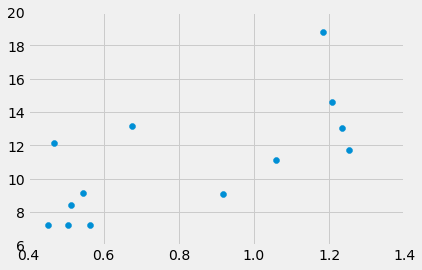

In [21]:
plt.scatter(food_price_imports['food_price'],food_price_imports['food_imports_percent'])
plt.show()

### Normalization

In [22]:
date = food_price_imports.index

In [23]:
scaler = MinMaxScaler()

In [24]:
food_price_imports = scaler.fit_transform(food_price_imports)
food_price_imports = pd.DataFrame(food_price_imports)
food_price_imports['date'] = date
food_price_imports.set_index('date', inplace=True)
food_price_imports.columns = ['food_price', 'food_imports_percent']
food_price_imports.head()

,food_price,food_imports_percent
date,,
2008-01-01,0.138512,0.000000
2009-01-01,0.000000,0.001569
2010-01-01,0.066530,0.003137
2011-01-01,0.117426,0.168102
2012-01-01,0.019321,0.425453


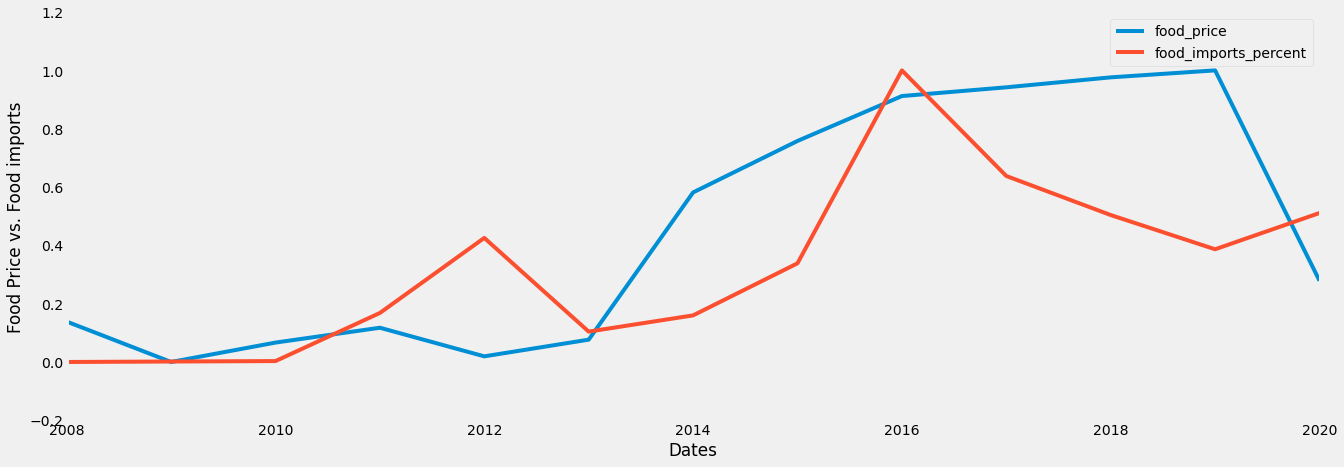

In [25]:
line_ax = food_price_imports.plot(kind='line', figsize=(20, 7))
line_ax.set_ylabel('Food Price vs. Food imports')
line_ax.set_xlabel('Dates')
line_ax.grid()

<span style="color:red">There is some positive relation between Food Price and Food import Percentage</span>